In [25]:
# guarda como download_binance_monthly.py
import requests
from datetime import datetime

def months(start, end):
    y,m = map(int, start.split('-'))
    y2,m2 = map(int, end.split('-'))
    while (y < y2) or (y==y2 and m<=m2):
        yield f"{y:04d}-{m:02d}"
        m += 1
        if m==13:
            m = 1
            y += 1

base = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/"
for ym in months("2023-01","2025-01"):
    fname = f"BTCUSDT-1m-{ym}.zip"
    url = base + fname
    r = requests.get(url, stream=True)
    if r.status_code == 200:
        with open(fname,'wb') as f:
            for chunk in r.iter_content(1024*1024):
                f.write(chunk)
        print("Descargado", fname)
    else:
        print("No encontrado:", fname, "status", r.status_code)


Descargado BTCUSDT-1m-2023-01.zip
Descargado BTCUSDT-1m-2023-02.zip
Descargado BTCUSDT-1m-2023-03.zip
Descargado BTCUSDT-1m-2023-04.zip
Descargado BTCUSDT-1m-2023-05.zip
Descargado BTCUSDT-1m-2023-06.zip
Descargado BTCUSDT-1m-2023-07.zip
Descargado BTCUSDT-1m-2023-08.zip
Descargado BTCUSDT-1m-2023-09.zip
Descargado BTCUSDT-1m-2023-10.zip
Descargado BTCUSDT-1m-2023-11.zip
Descargado BTCUSDT-1m-2023-12.zip
Descargado BTCUSDT-1m-2024-01.zip
Descargado BTCUSDT-1m-2024-02.zip
Descargado BTCUSDT-1m-2024-03.zip
Descargado BTCUSDT-1m-2024-04.zip
Descargado BTCUSDT-1m-2024-05.zip
Descargado BTCUSDT-1m-2024-06.zip
Descargado BTCUSDT-1m-2024-07.zip
Descargado BTCUSDT-1m-2024-08.zip
Descargado BTCUSDT-1m-2024-09.zip
Descargado BTCUSDT-1m-2024-10.zip
Descargado BTCUSDT-1m-2024-11.zip
Descargado BTCUSDT-1m-2024-12.zip
Descargado BTCUSDT-1m-2025-01.zip


In [27]:
import zipfile
import os
import pandas as pd

np.random.seed(2026)
# Carpeta donde tienes todos los .zip
carpeta = "./"   # cámbiala si es necesario

# Lista de todos los archivos .zip
zips = sorted([f for f in os.listdir(carpeta) if f.endswith(".zip")])

# Lista para acumular los valores de la 3ra columna
columna3_total = []

for z in zips:
    with zipfile.ZipFile(os.path.join(carpeta, z), 'r') as zf:
        # normalmente cada zip trae un csv con el mismo nombre que el zip pero .csv
        for nombre in zf.namelist():
            if nombre.endswith(".csv"):
                # Leer csv dentro del zip directamente con pandas
                df = pd.read_csv(zf.open(nombre), header=None)
                # Tomar la 3ra columna (índice 2 en Python)
                columna3 = df.iloc[:, 2]
                # Guardar en la lista
                columna3_total.extend(columna3.values)

# Crear DataFrame final
df_final = pd.DataFrame(columna3_total, columns=["Columna3"])
df_final
# Guardar a un CSV
df_final.to_csv("columna3_total.csv", index=False)
df_final
# 1. Montar Google Drive (solo necesario en Google Colab)
from google.colab import drive
drive.mount('/content/drive')

# 2. Guardar el DataFrame como CSV en una carpeta de tu Drive
ruta_guardado = "/content/drive/MyDrive/columna3_total.csv"

# Guardar el archivo
df_final.to_csv(ruta_guardado, index=False)

# Confirmación
print(f"Archivo guardado permanentemente en Google Drive: {ruta_guardado}")
#print("Archivo guardado: columna3_total.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archivo guardado permanentemente en Google Drive: /content/drive/MyDrive/columna3_total.csv


tienes una **serie de tiempo diaria del Bitcoin** con las siguientes columnas:

- `Fecha`
- `Último` (precio de cierre)
- `Apertura`
- `Máximo`
- `Mínimo`
- `Vol.` (volumen)
- `% var.` (variación porcentual)

Tu objetivo es **estimar los parámetros del modelo SDE con saltos + Cramér–Lundberg**, específicamente:

- \( \lambda \) (intensidad de saltos),
- \( \sigma \) (volatilidad difusiva),
- \( c \) (tasa de prima/ingreso continuo — opcional en finanzas),
- Distribución de \( Y_i \) (saltos).

---

## ✅ Estrategia para estimar parámetros usando tus datos

Dado que estás trabajando con **datos diarios**, debemos adaptar las técnicas para obtener estimaciones lo más robustas posible.

---

# 🔧 PASO 1: Preprocesamiento de los datos

### Objetivo:
Convertir los precios en log-retornos y prepararlos para el análisis.



In [28]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
# 1. Montar Google Drive (solo necesario en Google Colab)
from google.colab import drive
drive.mount('/content/drive')

# Cargar el archivo CSV en un DataFrame
df = pd.read_csv("/content/drive/MyDrive/data_bitcoin.csv")

# Mostrar las primeras filas para confirmar la estructura
print(df.head())

# Si el archivo solo tiene una columna llamada "columna3"
# renombramos para más claridad
df.columns = ["valor"]
df = df.drop(index=0).reset_index(drop=True)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
   Columna3
0  16544.76
1  16544.41
2  16541.17
3  16537.28
4  16536.08


In [ ]:
# Crear gráfico de línea con Plotly
fig = px.line(df, y="valor", title="Precio del Bitcoin")

# Mostrar gráfico interactivo
fig.show()

In [24]:
df

,valor,fecha
0,Columna3,2023-01-01 00:00:00
1,16544.76,2023-01-01 00:01:00
2,16544.41,2023-01-01 00:02:00
3,16541.17,2023-01-01 00:03:00
4,16537.28,2023-01-01 00:04:00
...,...,...
1052636,94153.05,2024-12-31 23:56:00
1052637,94068.46,2024-12-31 23:57:00
1052638,94011.93,2024-12-31 23:58:00
1052639,93982.21,2024-12-31 23:59:00


In [ ]:
#import pandas as pd
#import plotly.express as px

# === 1. Cargar archivo CSV ===
df = pd.read_csv("/content/drive/MyDrive/data_bitcoin.csv", names=["valor"])  # si no tiene encabezado
#df
# Si ya tiene encabezado, quita `names=["valor"]`

# === 2. Crear rango de fechas (1 dato por minuto) ===
fechas = pd.date_range(start="2023-01-01", end="2025-01-01", freq="min")  # "T" = minutos
fechas
# Asegurar que longitud coincida
df = df.iloc[:len(fechas)]
df
df["fecha"] = fechas
# === 3. Re-sampleo diario: tomar último valor de cada día ===
#df_diario = df.set_index("fecha").resample("1D").last()
#df_diario

fig = px.line(df, x = "fecha", y="valor", title="Precio del Bitcoin")
fig.show()


In [ ]:
df

,valor,fecha
0,Columna3,2023-01-01 00:00:00
1,16544.76,2023-01-01 00:01:00
2,16544.41,2023-01-01 00:02:00
3,16541.17,2023-01-01 00:03:00
4,16537.28,2023-01-01 00:04:00
...,...,...
1052636,94153.05,2024-12-31 23:56:00
1052637,94068.46,2024-12-31 23:57:00
1052638,94011.93,2024-12-31 23:58:00
1052639,93982.21,2024-12-31 23:59:00


In [ ]:
#import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#df = df.drop(index=0).reset_index(drop=True)
#df
# Suponiendo que ya cargaste los datos como un DataFrame 'df'
#df[''] = pd.to_datetime(df['fecha'])
#df.set_index('fecha', inplace=True)
df['valor'] = pd.to_numeric(df['valor'], errors='coerce')
# Calcular log-retornos diarios (útil para modelar variación cuadrática)
df['log_retorno'] = np.log(df['valor'] / df['valor'].shift(1))

# Eliminar primer valor (NaN)
df = df.dropna()

# Tamaño del paso de tiempo (en años)
dt = 1/365  # Asumiendo 252 días hábiles al año
T = len(df) * dt  # Horizonte temporal total en años

# 🔍 PASO 2: Estimación de la volatilidad continua $\sigma$ y detección de saltos

Como mencionamos antes, con datos diarios, la **variación bipotencia** tiene baja potencia, pero aún puede usarse con precaución.

## 📊 Método 1: Variación bipotencia (Barndorff-Nielsen & Shephard, 2004)

> ⚠️ Nota: En datos diarios, `jump_variation` puede ser negativo o muy pequeño → indica que los saltos están enmascarados. Esto es común.


In [ ]:
def bipower_variation(retornos):
    n = len(retornos)
    bv = 0.0 # Initialize bv to 0.0
    for i in range(1, n):
        bv += np.abs(retornos.iloc[i]) * np.abs(retornos.iloc[i-1])
    return (np.pi / 2) * bv / (n - 1)

# Estimar sigma^2 (varianza continua)
sigma2_hat = bipower_variation(df['log_retorno'])

In [ ]:
# Alternativamente, usar la variación cuadrática total
qv_total = np.sum(df['log_retorno']**2)

# Estimador de variación de saltos
jump_variation = qv_total - sigma2_hat

print(f"Variación cuadrática total: {qv_total:.9f}")
print(f"Variación bipotencia (continua): {sigma2_hat:.9f}")
print(f"Variación de saltos: {jump_variation:.9f}")

Variación cuadrática total: 0.375510874
Variación bipotencia (continua): 0.000000305
Variación de saltos: 0.375510570


## 🎯 Método 2: Detección de saltos por umbral (más práctico para datos diarios)

Usamos un umbral basado en la volatilidad histórica.



In [ ]:
# Estimar volatilidad diaria (como proxy de sigma)
sigma_daily = df['log_retorno'].std()

# Umbral: 3 desviaciones estándar (ajustable)
threshold = 3 * sigma_daily

# Detectar saltos (retornos extremos)
df['es_salto'] = np.abs(df['log_retorno']) > threshold
num_saltos = df['es_salto'].sum()

# Estimar lambda (saltos por año)
lambda_hat = num_saltos / T

print(f"Saltos detectados: {num_saltos}")
print(f"Estimación de lambda: {lambda_hat:.2f} saltos/año")

Saltos detectados: 17167
Estimación de lambda: 5.95 saltos/año


/tmp/ipykernel_1069/739917609.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['es_salto'] = np.abs(df['log_retorno']) > threshold


# 📈 PASO 3: Estimación de la distribución de los saltos $(Y_i)$

Una vez detectados los saltos, podemos analizar sus características:



Estadísticas de los saltos:
Media: 0.000459307
Desviación estándar: 0.003111096
Mediana: 0.001886770
Min: -0.035268372, Max: 0.034724824


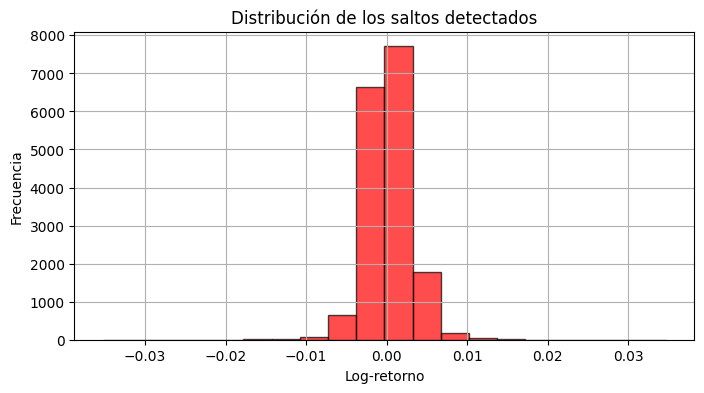

In [ ]:
# Extraer los retornos que se consideran saltos
saltos = df[df['es_salto']]['log_retorno']

if len(saltos) > 0:
    print("Estadísticas de los saltos:")
    print(f"Media: {saltos.mean():.9f}")
    print(f"Desviación estándar: {saltos.std():.9f}")
    print(f"Mediana: {saltos.median():.9f}")
    print(f"Min: {saltos.min():.9f}, Max: {saltos.max():.9f}")

    # Histograma
    plt.figure(figsize=(8,4))
    plt.hist(saltos, bins=20, color='red', alpha=0.7, edgecolor='black')
    plt.title('Distribución de los saltos detectados')
    plt.xlabel('Log-retorno')
    plt.ylabel('Frecuencia')
    plt.grid(True)
    plt.show()
else:
    print("No se detectaron saltos con el umbral actual.")

# 🔄 PASO 4: Estimación de la tasa de ingreso (\(c\)) — ¿necesaria?

En el contexto financiero, **el término \(c\) no suele tener sentido** como "prima" (como en seguros). Sin embargo, si deseas modelar un **drift** (tendencia), puedes estimarlo como:


In [ ]:
# Drift (media de los retornos diarios)
mu_hat = df['log_retorno'].mean() / dt  # anualizado
print(f"Drift estimado (mu): {mu_hat:.9f} por año")

Drift estimado (mu): 0.000602370 por año


> 📌 En modelos financieros, esto sería el “rendimiento esperado” del activo, no una prima de seguro.

In [ ]:
# 📊 PASO 5: Visualización y validación

KeyError: "None of [Index([      2,       3,       4,       5,       6,       7,       8,       9,\n            10,      11,\n       ...\n       1052631, 1052632, 1052633, 1052634, 1052635, 1052636, 1052637, 1052638,\n       1052639, 1052640],\n      dtype='int64', length=1052639)] are in the [columns]"

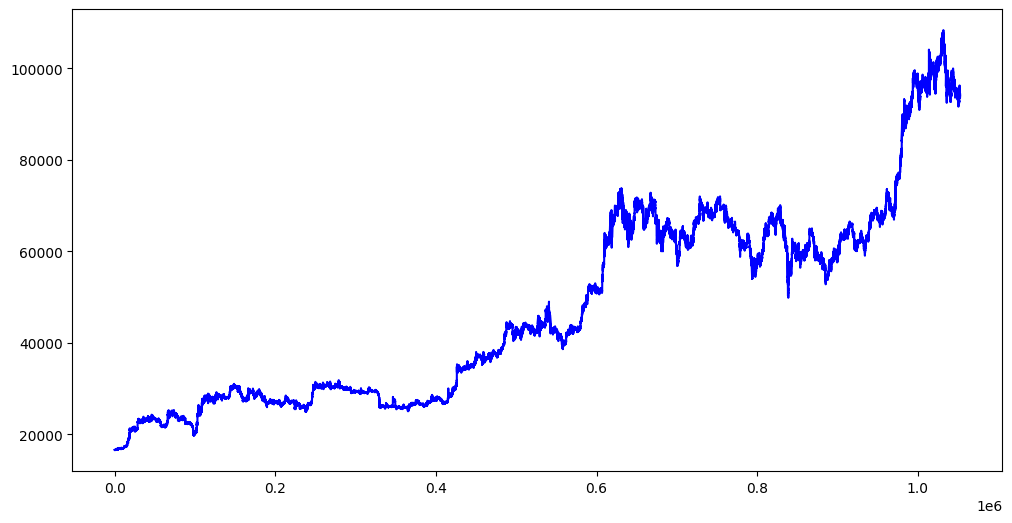

In [ ]:
# Gráfico de precios y saltos detectados
plt.figure(figsize=(12,6))
plt.plot(df.index, df['valor'], label='Precio BTC', color='blue')
plt.scatter(df[df['es_salto'].index], df[df['es_salto']]['valor'],
            color='red', marker='x', s=100, label='Salto detectado')
plt.title('Precio de Bitcoin con saltos detectados')
plt.legend()
plt.grid(True)
plt.show()

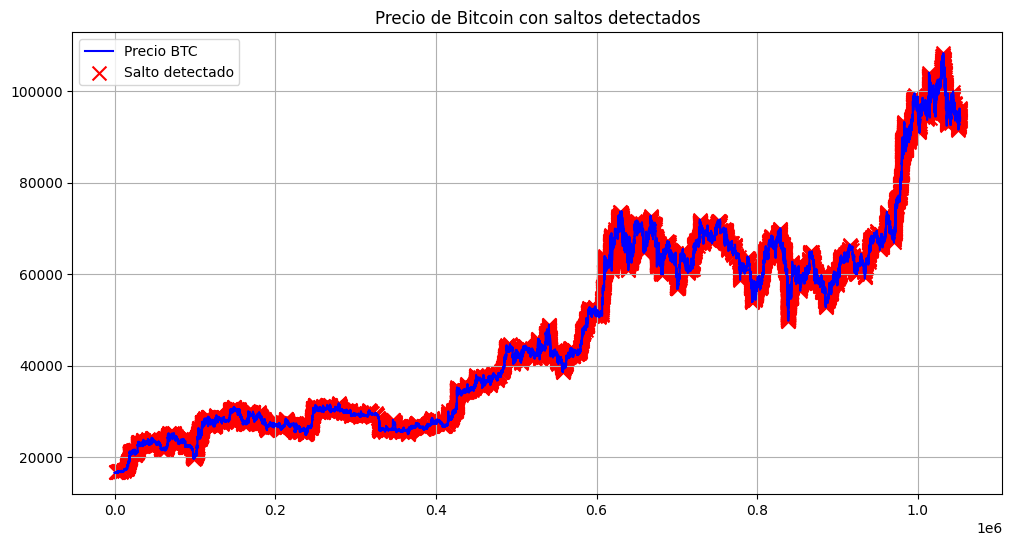

In [ ]:
# Gráficos
plt.figure(figsize=(12,6))
plt.plot(df.index, df['valor'], label='Precio BTC', color='blue')
plt.scatter(df[df['es_salto']].index, df[df['es_salto']]['valor'],
            color='red', marker='x', s=100, label='Salto detectado')
plt.title('Precio de Bitcoin con saltos detectados')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
df

,valor,fecha,log_retorno,es_salto
2,16544.41,2023-01-01 00:02:00,-0.000021,False
3,16541.17,2023-01-01 00:03:00,-0.000196,False
4,16537.28,2023-01-01 00:04:00,-0.000235,False
5,16536.08,2023-01-01 00:05:00,-0.000073,False
6,16537.80,2023-01-01 00:06:00,0.000104,False
...,...,...,...,...
1052636,94153.05,2024-12-31 23:56:00,-0.000064,False
1052637,94068.46,2024-12-31 23:57:00,-0.000899,False
1052638,94011.93,2024-12-31 23:58:00,-0.000601,False
1052639,93982.21,2024-12-31 23:59:00,-0.000316,False


In [ ]:
import plotly.graph_objects as go
import pandas as pd
import numpy as np

# Suponiendo que ya tienes el DataFrame 'df' con las columnas:
# - 'Último' (precio de cierre)
# - 'es_salto' (booleano que indica si ese día se detectó un salto)

# Crear la figura
fig = go.Figure()

# Añadir la serie de precios
fig.add_trace(go.Scatter(
    x=df.index,
    y=df['valor'],
    mode='lines',
    name='Precio BTC',
    line=dict(color='blue', width=2)
))

# Añadir los saltos detectados
saltos_df = df[df['es_salto']]
fig.add_trace(go.Scatter(
    x=saltos_df.index,
    y=saltos_df['valor'],
    mode='markers',
    name='Salto detectado',
    marker=dict(
        color='red',
        symbol='x',
        size=5,
        line=dict(width=1, color='black')
    )
))

# Configurar el diseño
fig.update_layout(
    title='Precio de Bitcoin con saltos detectados',
    xaxis_title='Fecha',
    yaxis_title='Precio (USD)',
    hovermode='x unified',
    legend=dict(x=0.01, y=0.99),
    template='plotly_white'
)

# Mostrar el gráfico
fig.show()

In [ ]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import os
import requests
import zipfile

# ==========================================
# FASE 0: DESCARGA Y CARGA DE DATOS BINANCE
# ==========================================
def download_and_load_binance():
    csv_path = "btc_daily_close.csv"
    if os.path.exists(csv_path):
        print("✅ Cargando datos históricos de Bitcoin desde CSV local...")
        df = pd.read_csv(csv_path, parse_dates=['fecha'])
        return df

    print("⚠️ CSV no encontrado. Iniciando descarga de datos minutales de Binance (2023-2025)...")
    def months(start, end):
        y, m = map(int, start.split('-'))
        y2, m2 = map(int, end.split('-'))
        while (y < y2) or (y == y2 and m <= m2):
            yield f"{y:04d}-{m:02d}"
            m += 1
            if m == 13:
                m = 1
                y += 1

    base = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/"
    zips = []
    for ym in months("2023-01", "2025-01"):
        fname = f"BTCUSDT-1m-{ym}.zip"
        url = base + fname
        r = requests.get(url, stream=True)
        if r.status_code == 200:
            with open(fname, 'wb') as f:
                for chunk in r.iter_content(1024 * 1024):
                    f.write(chunk)
            zips.append(fname)
        else:
            print(f"No encontrado: {fname}")

    columna3_total = []
    for z in zips:
        with zipfile.ZipFile(z, 'r') as zf:
            for nombre in zf.namelist():
                if nombre.endswith(".csv"):
                    df_zip = pd.read_csv(zf.open(nombre), header=None)
                    columna3_total.extend(df_zip.iloc[:, 2].values)  # Columna 3: Close

    df_min = pd.DataFrame(columna3_total, columns=["valor"])
    fechas = pd.date_range(start="2023-01-01", periods=len(df_min), freq="min")
    df_min["fecha"] = fechas

    df = df_min.set_index("fecha").resample("1D").last().dropna().reset_index()
    df.to_csv(csv_path, index=False)
    print("✅ Datos descargados, resampleados a diario y guardados en 'btc_daily_close.csv'")
    return df


df = download_and_load_binance()
df['valor'] = pd.to_numeric(df['valor'], errors='coerce')
df = df.dropna().reset_index(drop=True)

# ==========================================
# FASE 1: CALIBRACIÓN NO PARAMÉTRICA
# ==========================================
print("\n--- Calibrando parámetros (Variación Bipotencia + Umbral 4σ) ---")
df['log_retorno'] = np.log(df['valor'] / df['valor'].shift(1))
df = df.dropna().reset_index(drop=True)

dt = 1 / 365
T = len(df) * dt


def bipower_variation(retornos):
    """Devuelve la varianza continua PROMEDIO POR DÍA (normalizada por (n-1)).
    Se necesita en esta escala porque se usa como sigma_daily constante en la
    simulación diaria; NO debe compararse directamente contra una suma sin
    normalizar (ver FIX 2 más abajo)."""
    n = len(retornos)
    r = retornos.values
    bv = np.sum(np.abs(r[1:]) * np.abs(r[:-1]))  # vectorizado (antes: bucle for en Python)
    return (np.pi / 2) * bv / (n - 1)


sigma2_hat = bipower_variation(df['log_retorno'])

# --- FIX 2: comparar QV y BV en la MISMA escala (promedio por día) --------
# Antes: qv_total (suma total, ~n veces más grande) se restaba directamente
# de sigma2_hat (promedio por día), haciendo que jump_variation ≈ qv_total
# casi siempre (mezcla de escalas, resultado sin sentido).
n_obs = len(df)
qv_total = np.sum(df['log_retorno'] ** 2)
qv_avg = qv_total / (n_obs - 1)                      # ahora en la misma escala que sigma2_hat
jump_variation_avg = max(0.0, qv_avg - sigma2_hat)   # variación de saltos, promedio por día
jump_share_pct = 100 * jump_variation_avg / qv_avg if qv_avg > 0 else 0.0
# ---------------------------------------------------------------------------

sigma_daily = np.sqrt(sigma2_hat)
threshold = 4 * sigma_daily

df['es_salto'] = np.abs(df['log_retorno']) > threshold
num_saltos = int(df['es_salto'].sum())
lambda_hat = num_saltos / T

saltos = df[df['es_salto']]['log_retorno']
jump_mean = saltos.mean() if len(saltos) > 0 else 0.0
jump_std = saltos.std() if len(saltos) > 0 else 0.0

mu_total_hat = df['log_retorno'].mean() / dt
mu_cont_hat = mu_total_hat - (lambda_hat * jump_mean)

print(f"Volatilidad continua diaria (sigma):       {sigma_daily:.6f}")
print(f"Intensidad de saltos (lambda):              {lambda_hat:.2f} saltos/año")
print(f"Media de saltos (jump_mean):                {jump_mean:.6f}")
print(f"Drift TOTAL observado (mu_total, anualiz.):  {mu_total_hat:.4f}")
print(f"Drift continuo puro (mu_c, anualiz.):        {mu_cont_hat:.4f}  (solo diagnóstico, NO se usa como driver de la simulación)")
print(f"Variación de saltos / Variación cuadrática:  {jump_share_pct:.1f}%  (ambas en la misma escala, promedio diario)")

# ==========================================
# FASE 2: SIMULACIÓN MILSTEIN COMPENSADO
# ==========================================
T_hist = 2.0
N_hist = int(T_hist / dt)
N_sim = 1000
forecast_days = 30
X0 = df['valor'].iloc[0]

print(f"\n🚀 Simulando {N_sim} trayectorias con Método de Milstein Compensado...")

X_mil_hist = np.zeros((N_sim, N_hist + 1))
X_mil_fc = np.zeros((N_sim, forecast_days + 1))
X_mil_hist[:, 0] = X0

# --- FIX 1: doble compensación del drift -----------------------------------
# Antes: drift_mil = mu_cont_hat * x * dt   (mu_cont_hat YA tenía restada la
#        contribución esperada de los saltos: lambda_hat*jump_mean)
#        y ADEMÁS se restaba otra vez vía 'comp = -(lambda_hat*jump_mean)*dt'.
#        comp y E[jump_pct] se cancelan exactamente, por lo que el drift
#        efectivo terminaba siendo mu_cont_hat en vez de mu_total_hat: la
#        contribución esperada de los saltos se restaba DOS veces.
# Ahora: el drift base usa mu_total_hat (el drift total observado). El
#        término 'comp' compensa el proceso de saltos para que
#        (jump_pct + comp) tenga media cero, tal como exige la Ec. (2) del
#        marco teórico (a(t,Y) - ∫R·ν(dz)) — sin restar el aporte de saltos
#        una segunda vez.
DRIFT_ANUALIZADO = mu_total_hat
# -----------------------------------------------------------------------------

for sim in range(N_sim):
    for i in range(N_hist):
        x_mil = X_mil_hist[sim, i]
        dW = np.sqrt(dt) * np.random.randn()
        n_jumps = np.random.poisson(lambda_hat * dt)
        jump_pct = np.sum(np.random.normal(jump_mean, jump_std, n_jumps)) if n_jumps > 0 else 0.0
        comp = -(lambda_hat * jump_mean) * dt

        drift_mil = DRIFT_ANUALIZADO * x_mil * dt   # FIX: antes mu_cont_hat
        diff_mil = sigma_daily * x_mil * dW
        corr_mil = 0.5 * (sigma_daily ** 2) * x_mil * (dW ** 2 - dt)

        X_mil_hist[sim, i + 1] = max(10.0, x_mil + drift_mil + diff_mil + corr_mil + (x_mil * comp) + (x_mil * jump_pct))

# Bucle Pronóstico
U0_mil = np.median(X_mil_hist[:, -1])
X_mil_fc[:, 0] = U0_mil

for sim in range(N_sim):
    for i in range(forecast_days):
        u_mil = X_mil_fc[sim, i]
        dW = np.sqrt(dt) * np.random.randn()
        n_jumps = np.random.poisson(lambda_hat * dt)
        jump_pct = np.sum(np.random.normal(jump_mean, jump_std, n_jumps)) if n_jumps > 0 else 0.0
        comp = -(lambda_hat * jump_mean) * dt

        X_mil_fc[sim, i + 1] = max(
            10.0,
            u_mil
            + DRIFT_ANUALIZADO * u_mil * dt          # FIX: antes mu_cont_hat
            + sigma_daily * u_mil * dW
            + 0.5 * (sigma_daily ** 2) * u_mil * (dW ** 2 - dt)
            + u_mil * comp
            + u_mil * jump_pct,
        )

# ==========================================
# FASE 3: ESTADÍSTICAS, DETECCIÓN DE SALTOS Y VISUALIZACIÓN
# ==========================================
med_mil_h = np.median(X_mil_hist, axis=0)
p05_mil_h = np.percentile(X_mil_hist, 5, axis=0)
p95_mil_h = np.percentile(X_mil_hist, 95, axis=0)

med_mil_f = np.median(X_mil_fc, axis=0)
p05_mil_f = np.percentile(X_mil_fc, 5, axis=0)
p95_mil_f = np.percentile(X_mil_fc, 95, axis=0)

t_hist = np.arange(N_hist + 1)
t_fc = np.arange(N_hist, N_hist + forecast_days + 1)


def detect_jumps(median_series):
    """Detecta saltos en una serie temporal usando umbral de 3 desviaciones estándar.
    NOTA (limitación conocida, no corregida aquí): sobre ventanas cortas (p. ej.
    los 30 días del pronóstico) este umbral, al recalcularse sobre la propia
    submuestra, pierde poder discriminante y tiende a sobre-detectar."""
    log_returns = np.log(median_series[1:] / median_series[:-1])
    threshold_sim = 3 * np.std(log_returns)
    jump_flags = np.abs(log_returns) > threshold_sim
    jump_indices = np.where(jump_flags)[0] + 1
    jump_times = np.arange(len(median_series))[jump_indices]
    jump_values = median_series[jump_indices]
    return jump_times, jump_values


jump_times_hist, jump_values_hist = detect_jumps(med_mil_h)
jump_times_fc, jump_values_fc = detect_jumps(med_mil_f)

# ==========================================
# VISUALIZACIÓN CON ZOOM TIPO LUPA (solo cambia la PRESENTACIÓN)
#   Vista completa + recuadro ampliado del pronóstico superpuesto en la zona
#   vacía superior izquierda. El zoom es un segundo par de ejes vectoriales
#   (no una imagen), así que no pierde calidad.
# ==========================================
import math
ESTILO_ZOOM = "lupa"          # "lupa" (líneas de enlace, como la flor) o "flecha" (flecha curva, como la abeja)
COLOR_ZOOM = "#6A1B9A"        # color del marco de zoom
N_TRAY_ZOOM = 25              # trayectorias individuales del pronóstico (ilustrativas)
DIAS_PREVIOS_ZOOM = 5         # días del histórico visibles en el zoom antes del pronóstico
INSET_X = (0.07, 0.50)        # posición horizontal del recuadro (fracción del área de la gráfica)
INSET_Y_ARRIBA = 0.92         # borde superior del recuadro (deja sitio para su etiqueta)

precio_real = df['valor'].values
n_p = min(len(precio_real), N_hist + 1)      # puntos del precio real que caen en el histórico


def paso_bonito(span, n=5):
    """Paso 1-2-5 x 10^k para la cuadrícula del zoom."""
    crudo = span / n
    base = 10 ** math.floor(math.log10(crudo))
    for f in (1, 2, 5, 10):
        if crudo <= f * base:
            return f * base
    return 10 * base


# ---- Rangos de la vista principal ----
xm0, xm1 = -5.0, N_hist + forecast_days + 25.0
ym_top = max(p95_mil_h.max(), p95_mil_f.max(), precio_real[:n_p].max())
ym_bot = min(p05_mil_h.min(), precio_real[:n_p].min())
ym0 = ym_bot - 0.03 * (ym_top - ym_bot)
ym1 = ym_top + 0.04 * (ym_top - ym_bot)
dX, dY = xm1 - xm0, ym1 - ym0


def paper_a_datos(px, py):
    return xm0 + px * dX, ym0 + py * dY


# El recuadro va en la zona vacía de arriba a la izquierda: su borde inferior
# queda por encima de la banda P95 y del precio real (con margen para los ticks)
ix0, _ = paper_a_datos(INSET_X[0], 0)
ix1, _ = paper_a_datos(INSET_X[1], 0)
mascara = (t_hist >= ix0) & (t_hist <= ix1)
techo = max(p95_mil_h[mascara].max(), precio_real[:n_p][mascara[:n_p]].max())
INSET_Y = (min((techo + 0.09 * dY - ym0) / dY, 0.60), INSET_Y_ARRIBA)
_, iy0 = paper_a_datos(0, INSET_Y[0])
_, iy1 = paper_a_datos(0, INSET_Y[1])

# ---- Ventana que se amplía ----
zx0 = N_hist - DIAS_PREVIOS_ZOOM
zx1 = N_hist + forecast_days + 0.8
cola_med = med_mil_h[zx0:]
cola_t = t_hist[zx0:]
cola_precio_t = t_hist[zx0:n_p]
cola_precio = precio_real[zx0:n_p]
vals = [p05_mil_f, p95_mil_f, cola_med] + ([cola_precio] if len(cola_precio) else [])
zlo = float(min(v.min() for v in vals))
zhi = float(max(v.max() for v in vals))
pad = 0.08 * (zhi - zlo)
zy0, zy1 = zlo - pad, zhi + pad
aumento = (INSET_Y[1] - INSET_Y[0]) / ((zy1 - zy0) / dY)

fig = go.Figure()

# =================== VISTA PRINCIPAL (igual que antes) ===================
fig.add_trace(go.Scatter(x=t_hist, y=df['valor'].values, mode='lines', line=dict(color='black', width=1.5, dash='dot'), name='Precio Real BTC'))
fig.add_trace(go.Scatter(x=np.concatenate([t_hist, t_hist[::-1]]), y=np.concatenate([p95_mil_h, p05_mil_h[::-1]]), fill='toself', fillcolor='rgba(247, 147, 26, 0.2)', line=dict(color='rgba(255,255,255,0)'), name='IC 90% Hist. Milstein', hoverinfo='skip'))
fig.add_trace(go.Scatter(x=t_hist, y=med_mil_h, mode='lines', line=dict(color='#F7931A', width=2.5), name='Mediana Hist. Milstein'))
if len(jump_times_hist) > 0:
    fig.add_trace(go.Scatter(
        x=jump_times_hist, y=jump_values_hist, mode='markers',
        marker=dict(color='red', size=8, symbol='x', line=dict(width=1, color='black')),
        name='Saltos Detectados (Hist.)'))
fig.add_trace(go.Scatter(x=np.concatenate([t_fc, t_fc[::-1]]), y=np.concatenate([p95_mil_f, p05_mil_f[::-1]]), fill='toself', fillcolor='rgba(0, 82, 151, 0.2)', line=dict(color='rgba(255,255,255,0)'), name='IC 90% Pron. Milstein', legendgroup='fb', hoverinfo='skip'))
fig.add_trace(go.Scatter(x=t_fc, y=med_mil_f, mode='lines', line=dict(color='#005297', width=2.5, dash='dash'), name='Mediana Pron. Milstein', legendgroup='fm'))
if len(jump_times_fc) > 0:
    fig.add_trace(go.Scatter(
        x=N_hist + jump_times_fc, y=jump_values_fc, mode='markers',
        marker=dict(color='blue', size=5, symbol='x', line=dict(width=1, color='black')),
        name='Saltos Detectados (Pron.)', legendgroup='fj'))

# =================== RECUADRO AMPLIADO (ejes x2, y2) ===================
Z = dict(xaxis='x2', yaxis='y2')
# 1) fondo blanco opaco que tapa la cuadrícula de atrás
fig.add_trace(go.Scatter(x=[zx0, zx1, zx1, zx0, zx0], y=[zy0, zy0, zy1, zy1, zy0],
                         fill='toself', fillcolor='white', line=dict(width=0), mode='lines',
                         hoverinfo='skip', showlegend=False, **Z))
# 2) cuadrícula propia
paso_y = paso_bonito(zy1 - zy0)
gx, gy = [], []
for v in np.arange(math.ceil(zy0 / paso_y) * paso_y, zy1, paso_y):
    gx += [zx0, zx1, None]
    gy += [v, v, None]
for xv in np.arange(math.ceil(zx0 / 5) * 5, zx1, 5):
    gx += [xv, xv, None]
    gy += [zy0, zy1, None]
fig.add_trace(go.Scatter(x=gx, y=gy, mode='lines', line=dict(color='#E3E3E3', width=1),
                         hoverinfo='skip', showlegend=False, **Z))
# 3) contenido
fig.add_trace(go.Scatter(x=np.concatenate([t_fc, t_fc[::-1]]), y=np.concatenate([p95_mil_f, p05_mil_f[::-1]]),
                         fill='toself', fillcolor='rgba(0, 82, 151, 0.2)', line=dict(color='rgba(0,0,0,0)'),
                         legendgroup='fb', showlegend=False, hoverinfo='skip', **Z))
for j in range(min(N_TRAY_ZOOM, X_mil_fc.shape[0])):
    fig.add_trace(go.Scatter(x=t_fc, y=X_mil_fc[j], mode='lines',
                             line=dict(color='rgba(0, 82, 151, 0.13)', width=0.8),
                             name=f'Trayectorias pronóstico ({N_TRAY_ZOOM})', legendgroup='ft',
                             showlegend=(j == 0), hoverinfo='skip', **Z))
if len(cola_precio):
    fig.add_trace(go.Scatter(x=cola_precio_t, y=cola_precio, mode='lines',
                             line=dict(color='black', width=1.8, dash='dot'), showlegend=False,
                             hovertemplate='Día %{x}<br>Precio real: $%{y:,.0f}<extra></extra>', **Z))
fig.add_trace(go.Scatter(x=cola_t, y=cola_med, mode='lines', line=dict(color='#F7931A', width=2.8),
                         showlegend=False, hovertemplate='Día %{x}<br>Mediana: $%{y:,.0f}<extra></extra>', **Z))
for serie, nombre in ((p95_mil_f, 'P95'), (p05_mil_f, 'P5')):
    fig.add_trace(go.Scatter(x=t_fc, y=serie, mode='lines', line=dict(color='#005297', width=1, dash='dot'),
                             showlegend=False, hovertemplate=nombre + ': $%{y:,.0f}<extra></extra>', **Z))
fig.add_trace(go.Scatter(x=t_fc, y=med_mil_f, mode='lines', line=dict(color='#005297', width=3, dash='dash'),
                         legendgroup='fm', showlegend=False,
                         hovertemplate='Día %{x}<br>Mediana: $%{y:,.0f}<extra></extra>', **Z))
if len(jump_times_fc) > 0:
    fig.add_trace(go.Scatter(x=N_hist + jump_times_fc, y=jump_values_fc, mode='markers',
                             marker=dict(color='blue', size=6, symbol='x', line=dict(width=0.6, color='black')),
                             legendgroup='fj', showlegend=False,
                             hovertemplate='Salto día %{x}<br>$%{y:,.0f}<extra></extra>', **Z))
fig.add_trace(go.Scatter(x=[N_hist], y=[U0_mil], mode='markers',
                         marker=dict(color='black', size=9, symbol='diamond'),
                         name='Condición inicial (U0)',
                         hovertemplate='U0 = $%{y:,.0f}<extra></extra>', **Z))

# =================== MARCOS Y ENLACE TIPO LUPA ===================
shapes = [
    # zona ampliada en la vista principal
    dict(type='rect', xref='x', yref='y', x0=zx0, x1=zx1, y0=zy0, y1=zy1,
         line=dict(color=COLOR_ZOOM, width=2), fillcolor='rgba(106, 27, 154, 0.08)', layer='above'),
    # marco del recuadro ampliado
    dict(type='rect', xref='paper', yref='paper', x0=INSET_X[0], x1=INSET_X[1],
         y0=INSET_Y[0], y1=INSET_Y[1], line=dict(color=COLOR_ZOOM, width=3), layer='above'),
    # inicio del pronóstico (vista principal y zoom)
    dict(type='line', xref='x', yref='y', x0=N_hist, x1=N_hist, y0=ym0, y1=ym1,
         line=dict(color='gray', dash='dot', width=1.5)),
    dict(type='line', xref='x2', yref='y2', x0=N_hist, x1=N_hist, y0=zy0, y1=zy1,
         line=dict(color='gray', dash='dot', width=1.5)),
]
if ESTILO_ZOOM == "lupa":
    # cono translúcido + dos líneas: esquinas izquierdas de la zona -> esquinas derechas del recuadro
    shapes.append(dict(type='path', xref='x', yref='y', layer='below',
                       path=f"M {zx0},{zy1} L {zx0},{zy0} L {ix1},{iy0} L {ix1},{iy1} Z",
                       fillcolor='rgba(106, 27, 154, 0.06)', line=dict(width=0)))
    for ya, yb in ((zy1, iy1), (zy0, iy0)):
        shapes.append(dict(type='line', xref='x', yref='y', layer='above',
                           x0=zx0, y0=ya, x1=ix1, y1=yb, line=dict(color=COLOR_ZOOM, width=1.8)))
else:
    # flecha curva punteada (como la abeja): de la zona ampliada al recuadro
    sx, sy = (zx0 + zx1) / 2, zy1
    ex, ey = ix1 + 0.01 * dX, (iy0 + iy1) / 2
    cx, cy = sx, iy1
    shapes.append(dict(type='path', xref='x', yref='y', layer='above',
                       path=f"M {sx},{sy} Q {cx},{cy} {ex},{ey}",
                       line=dict(color=COLOR_ZOOM, width=3, dash='dash')))
    fig.add_annotation(x=ex, y=ey, ax=ex + 0.04 * (cx - ex), ay=ey + 0.04 * (cy - ey),
                       xref='x', yref='y', axref='x', ayref='y', text='', showarrow=True,
                       arrowhead=2, arrowsize=1.6, arrowwidth=3, arrowcolor=COLOR_ZOOM)
fig.update_layout(shapes=shapes)

fig.add_annotation(x=N_hist, y=1.0, xref='x', yref='paper', text='Inicio Pronóstico (30 días)',
                   showarrow=False, xanchor='right', yanchor='top', xshift=-4, font=dict(size=11))
# etiqueta del zoom: justo encima del marco, fuera de los datos
fig.add_annotation(x=INSET_X[0], y=INSET_Y[1], xref='paper', yref='paper',
                   xanchor='left', yanchor='bottom', yshift=3, showarrow=False,
                   text=f"<b>Zoom: pronóstico a 30 días</b> · aumento vertical ≈ ×{aumento:.0f}",
                   font=dict(size=11, color=COLOR_ZOOM))
resumen = (f"Pronóstico 30 días · U0 = ${U0_mil:,.0f} · Mediana final = ${med_mil_f[-1]:,.0f}"
           f" · IC 90% = [${p05_mil_f[-1]:,.0f}, ${p95_mil_f[-1]:,.0f}]")

# =================== EJES Y DISEÑO ===================
fig.update_layout(
    title=dict(text="<b>Simulación BTC/USDT: Método de Milstein Compensado (CORREGIDO)</b>",
               subtitle=dict(text=f"<i>{resumen}</i>", font=dict(size=12)),
               x=0.5, xanchor='center', y=0.97, yanchor='top', font=dict(size=18)),
    xaxis=dict(domain=[0, 1], range=[xm0, xm1], title=dict(text='Días', standoff=8)),
    yaxis=dict(domain=[0, 1], range=[ym0, ym1], title='Precio USD'),
    xaxis2=dict(domain=list(INSET_X), anchor='y2', range=[zx0, zx1], dtick=5,
                showgrid=False, zeroline=False, tickfont=dict(size=10), ticks='outside'),
    yaxis2=dict(domain=list(INSET_Y), anchor='x2', range=[zy0, zy1], dtick=paso_y,
                tickformat='~s', showgrid=False, zeroline=False, tickfont=dict(size=10), ticks='outside'),
    height=780, width=1100, template="plotly_white", hovermode='closest',
    # leyenda DEBAJO de la gráfica: ya no se encima con el título
    legend=dict(orientation="h", x=0.5, xanchor="center", y=-0.11, yanchor="top",
                font=dict(size=11), entrywidth=215, entrywidthmode="pixels",
                bgcolor='rgba(255,255,255,0.9)'),
    margin=dict(l=80, r=40, t=105, b=150))
fig.show()
# fig.write_html("btc_milstein_zoom.html")          # opcional: guardar interactiva

# ==========================================
# FASE 4: RESUMEN MILSTEIN
# ==========================================
print("\n" + "=" * 60)
print("RESUMEN PRONÓSTICO A 30 DÍAS: MILSTEIN COMPENSADO (CORREGIDO)")
print("=" * 60)
print(f"{'Métrica':<35} | {'Valor':<20}")
print("-" * 60)
print(f"{'Precio Inicial (U0)':<35} | ${U0_mil:,.2f}")
print(f"{'Mediana Final Proyectada':<35} | ${med_mil_f[-1]:,.2f}")
print(f"{'Límite Inferior IC 90% (5%)':<35} | ${p05_mil_f[-1]:,.2f}")
print(f"{'Límite Superior IC 90% (95%)':<35} | ${p95_mil_f[-1]:,.2f}")
print(f"{'Ancho del Intervalo de Confianza':<35} | ${p95_mil_f[-1] - p05_mil_f[-1]:,.2f}")
print(f"{'Saltos detectados en Mediana (Hist.)':<35} | {len(jump_times_hist)}")
print(f"{'Saltos detectados en Mediana (Pron.)':<35} | {len(jump_times_fc)}")
print("=" * 60)

# ==========================================
# FASE 5: GUARDADO PARA LA FIGURA DEL PDF (nuevo; no altera nada de lo anterior)
# ==========================================
# Como la simulación no fija semilla, cada ejecución da trayectorias distintas.
# Se guardan las de ESTA ejecución para que 'grafica_zoom_pdf_btc.py' dibuje
# exactamente los mismos resultados que acabas de ver.
np.savez_compressed("trayectorias_btc_milstein.npz",
                    X_mil_hist=X_mil_hist, X_mil_fc=X_mil_fc,
                    precio_real=df['valor'].values, N_hist=N_hist, forecast_days=forecast_days)
print("Trayectorias guardadas en: trayectorias_btc_milstein.npz")

✅ Cargando datos históricos de Bitcoin desde CSV local...

--- Calibrando parámetros (Variación Bipotencia + Umbral 4σ) ---
Volatilidad continua diaria (sigma):       0.023843
Intensidad de saltos (lambda):              1.44 saltos/año
Media de saltos (jump_mean):                0.038932
Drift TOTAL observado (mu_total, anualiz.):  0.8722
Drift continuo puro (mu_c, anualiz.):        0.8162  (solo diagnóstico, NO se usa como driver de la simulación)
Variación de saltos / Variación cuadrática:  10.5%  (ambas en la misma escala, promedio diario)

🚀 Simulando 1000 trayectorias con Método de Milstein Compensado...



RESUMEN PRONÓSTICO A 30 DÍAS: MILSTEIN COMPENSADO (CORREGIDO)
Métrica                             | Valor               
------------------------------------------------------------
Precio Inicial (U0)                 | $92,761.72
Mediana Final Proyectada            | $99,236.05
Límite Inferior IC 90% (5%)         | $97,761.38
Límite Superior IC 90% (95%)        | $107,863.90
Ancho del Intervalo de Confianza    | $10,102.51
Saltos detectados en Mediana (Hist.) | 679
Saltos detectados en Mediana (Pron.) | 30
Trayectorias guardadas en: trayectorias_btc_milstein.npz


In [ ]:
# =============================================================================
# GRÁFICA PARA PDF (matplotlib) - BTC/USDT Milstein compensado con zoom tipo lupa
#
# NO simula nada: lee las trayectorias que guarda btc_milstein_zoom.py
#   trayectorias_btc_milstein.npz
# y calcula mediana, IC 90 % (P5-P95) y saltos en la mediana con la MISMA regla
# (3 desv. est. de los log-rendimientos de la mediana).
#
# Salidas:
#   btc_milstein_zoom.pdf  -> vectorial (no pierde calidad en LaTeX/PDF)
#   btc_milstein_zoom.png  -> 300 dpi
# =============================================================================
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, FancyArrowPatch
from matplotlib.ticker import FuncFormatter, MultipleLocator

ARCHIVO_NPZ = "trayectorias_btc_milstein.npz"
SALIDA = "btc_milstein_zoom"

# ---- Opciones de presentación ----
ESTILO_ZOOM = "lupa"        # "lupa" (como la flor) o "flecha" (como la abeja)
COLOR_ZOOM = "#6A1B9A"
N_TRAY_ZOOM = 25
DIAS_PREVIOS_ZOOM = 5
INSET_X = (0.07, 0.50)      # posición horizontal del recuadro (fracción de los ejes)
INSET_Y_ARRIBA = 0.92       # deja sitio arriba para la etiqueta del zoom

# ---------------------------------------------------------------------------
d = np.load(ARCHIVO_NPZ)
X_hist, X_fc, precio = d["X_mil_hist"], d["X_mil_fc"], d["precio_real"]
N_hist, forecast_days = int(d["N_hist"]), int(d["forecast_days"])

med_h, p05_h, p95_h = (np.median(X_hist, 0), np.percentile(X_hist, 5, 0), np.percentile(X_hist, 95, 0))
med_f, p05_f, p95_f = (np.median(X_fc, 0), np.percentile(X_fc, 5, 0), np.percentile(X_fc, 95, 0))
U0 = X_fc[0, 0]
t_hist = np.arange(N_hist + 1)
t_fc = np.arange(N_hist, N_hist + forecast_days + 1)
n_p = min(len(precio), N_hist + 1)


def detect_jumps(s):
    lr = np.log(s[1:] / s[:-1])
    idx = np.where(np.abs(lr) > 3 * np.std(lr))[0] + 1
    return np.arange(len(s))[idx], s[idx]


jt_h, jv_h = detect_jumps(med_h)
jt_f, jv_f = detect_jumps(med_f)

fmt_k = FuncFormatter(lambda v, _: f"{v/1000:,.0f}k" if abs(v) >= 1000 else f"{v:,.0f}")
fmt_k1 = FuncFormatter(lambda v, _: f"{v/1000:,.1f}k")

C_HB, C_HL = "#F7931A", "#F7931A"
C_FB, C_FL = "#005297", "#005297"

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.edgecolor": "#888", "axes.linewidth": 0.8})
fig, ax = plt.subplots(figsize=(11, 7.8))
ax.set_facecolor("white")

# ---------------- Vista principal ----------------
ax.plot(t_hist[:n_p], precio[:n_p], color="black", lw=1.2, ls=":", zorder=3)
ax.fill_between(t_hist, p05_h, p95_h, color=C_HB, alpha=0.20, lw=0, zorder=1)
ax.plot(t_hist, med_h, color=C_HL, lw=2.2, zorder=4)
ax.scatter(jt_h, jv_h, marker="X", color="red", edgecolor="black", lw=0.5, s=45, zorder=5)
ax.fill_between(t_fc, p05_f, p95_f, color=C_FB, alpha=0.20, lw=0, zorder=1)
ax.plot(t_fc, med_f, color=C_FL, lw=2.2, ls="--", zorder=4)
ax.scatter(N_hist + jt_f, jv_f, marker="x", color="blue", s=14, lw=1, zorder=5)

xm0, xm1 = -5.0, N_hist + forecast_days + 25.0
ym_top = max(p95_h.max(), p95_f.max(), precio[:n_p].max())
ym_bot = min(p05_h.min(), precio[:n_p].min())
ym0, ym1 = ym_bot - 0.03 * (ym_top - ym_bot), ym_top + 0.04 * (ym_top - ym_bot)
dX, dY = xm1 - xm0, ym1 - ym0
ax.set_xlim(xm0, xm1)
ax.set_ylim(ym0, ym1)
ax.yaxis.set_major_formatter(fmt_k)
ax.xaxis.set_major_locator(MultipleLocator(100))
ax.grid(True, color="#ECECEC", lw=0.8, zorder=0)
ax.set_xlabel("Días")
ax.set_ylabel("Precio USD")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)

# recuadro en la zona vacía superior izquierda, por encima de P95 y del precio real
ix0, ix1 = xm0 + INSET_X[0] * dX, xm0 + INSET_X[1] * dX
m = (t_hist >= ix0) & (t_hist <= ix1)
techo = max(p95_h[m].max(), precio[:n_p][m[:n_p]].max())
INSET_Y = (min((techo + 0.09 * dY - ym0) / dY, 0.60), INSET_Y_ARRIBA)

# ---------------- Recuadro ampliado ----------------
axz = ax.inset_axes([INSET_X[0], INSET_Y[0], INSET_X[1] - INSET_X[0], INSET_Y[1] - INSET_Y[0]])
axz.set_facecolor("white")
zx0, zx1 = N_hist - DIAS_PREVIOS_ZOOM, N_hist + forecast_days + 0.8
cola_med = med_h[zx0:]
cola_p_t, cola_p = t_hist[zx0:n_p], precio[zx0:n_p]
vals = [p05_f, p95_f, cola_med] + ([cola_p] if len(cola_p) else [])
zlo, zhi = min(v.min() for v in vals), max(v.max() for v in vals)
pad = 0.08 * (zhi - zlo)
zy0, zy1 = zlo - pad, zhi + pad

axz.fill_between(t_fc, p05_f, p95_f, color=C_FB, alpha=0.18, lw=0, zorder=1)
for j in range(min(N_TRAY_ZOOM, X_fc.shape[0])):
    axz.plot(t_fc, X_fc[j], color=C_FL, alpha=0.15, lw=0.7, zorder=2)
axz.plot(t_fc, p95_f, color=C_FL, lw=0.9, ls=":", zorder=3)
axz.plot(t_fc, p05_f, color=C_FL, lw=0.9, ls=":", zorder=3)
if len(cola_p):
    axz.plot(cola_p_t, cola_p, color="black", lw=1.6, ls=":", zorder=4)
axz.plot(t_hist[zx0:], cola_med, color=C_HL, lw=2.6, zorder=4)
axz.plot(t_fc, med_f, color=C_FL, lw=2.6, ls="--", zorder=4)
axz.scatter(N_hist + jt_f, jv_f, marker="x", color="blue", s=18, lw=1.0, zorder=5)
axz.scatter([N_hist], [U0], marker="D", color="black", s=35, zorder=6)
axz.axvline(N_hist, color="gray", ls=":", lw=1.3, zorder=3)
axz.set_xlim(zx0, zx1)
axz.set_ylim(zy0, zy1)
axz.xaxis.set_major_locator(MultipleLocator(5))
axz.yaxis.set_major_formatter(fmt_k1 if (zy1 - zy0) < 10_000 else fmt_k)
axz.grid(True, color="#E6E6E6", lw=0.7, zorder=0)
axz.tick_params(labelsize=8.5)
for s in axz.spines.values():
    s.set_edgecolor(COLOR_ZOOM)
    s.set_linewidth(2.5)
aumento = (INSET_Y[1] - INSET_Y[0]) / ((zy1 - zy0) / dY)
# etiqueta del zoom justo encima del marco (fuera de los datos)
axz.text(0.0, 1.015, f"Zoom: pronóstico a 30 días · aumento vertical ≈ ×{aumento:.0f}",
         transform=axz.transAxes, va="bottom", ha="left", fontsize=10,
         fontweight="bold", color=COLOR_ZOOM)

if ESTILO_ZOOM == "lupa":
    ind = ax.indicate_inset_zoom(axz, edgecolor=COLOR_ZOOM, lw=1.8)
    if isinstance(ind, tuple):                      # matplotlib < 3.10
        rect, conectores = ind
    else:                                           # matplotlib >= 3.10
        rect, conectores = ind.rectangle, ind.connectors
        ind.set_alpha(None)
    rect.set_alpha(None)
    rect.set_facecolor((0.42, 0.11, 0.6, 0.10))
    rect.set_edgecolor(COLOR_ZOOM)
    rect.set_linewidth(2)
    for c in conectores:
        c.set_alpha(None)
        c.set_color(COLOR_ZOOM)
        c.set_linewidth(1.6)
else:
    ax.add_patch(plt.Rectangle((zx0, zy0), zx1 - zx0, zy1 - zy0, fc=(0.42, 0.11, 0.6, 0.10),
                               ec=COLOR_ZOOM, lw=2, zorder=6))
    ax.add_patch(FancyArrowPatch(
        ((zx0 + zx1) / 2, zy1), (ix1 + 0.01 * dX, ym0 + (INSET_Y[0] + INSET_Y[1]) / 2 * dY),
        connectionstyle="arc3,rad=0.45", arrowstyle="-|>,head_length=10,head_width=6",
        color=COLOR_ZOOM, lw=2.5, ls="--", zorder=7))

ax.axvline(N_hist, color="gray", ls=":", lw=1.4, zorder=2)
ax.text(N_hist - 4, ym1 - 0.01 * dY, "Inicio Pronóstico (30 días)", ha="right", va="top", fontsize=9.5)

# ---------------- Títulos y leyenda ----------------
fig.suptitle("Simulación BTC/USDT: Método de Milstein Compensado (CORREGIDO)",
             fontsize=15, fontweight="bold", color="#2A3F5F", y=0.985)
ax.set_title(f"Pronóstico 30 días · U0 = ${U0:,.0f} · Mediana final = ${med_f[-1]:,.0f}"
             f" · IC 90% = [${p05_f[-1]:,.0f}, ${p95_f[-1]:,.0f}]".replace("$", r"\$"),
             fontsize=10.5, style="italic", color="#2A3F5F", pad=10)
handles = [Line2D([], [], color="black", ls=":", lw=1.5, label="Precio Real BTC"),
           Patch(color=C_HB, alpha=0.25, label="IC 90% Hist. Milstein"),
           Line2D([], [], color=C_HL, lw=2.2, label="Mediana Hist. Milstein"),
           Line2D([], [], marker="X", color="red", mec="black", ls="", ms=8, label="Saltos Detectados (Hist.)"),
           Patch(color=C_FB, alpha=0.25, label="IC 90% Pron. Milstein"),
           Line2D([], [], color=C_FL, lw=2.2, ls="--", label="Mediana Pron. Milstein"),
           Line2D([], [], marker="x", color="blue", ls="", ms=6, label="Saltos Detectados (Pron.)"),
           Line2D([], [], color=C_FL, alpha=0.4, lw=1, label=f"Trayectorias ({N_TRAY_ZOOM})"),
           Line2D([], [], marker="D", color="black", ls="", ms=5, label="Condición inicial (U0)")]
# leyenda DEBAJO de la gráfica: no se encima con el título ni con los datos
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=5,
          frameon=False, fontsize=9, columnspacing=1.4, handletextpad=0.5)

fig.tight_layout()
fig.savefig(f"{SALIDA}.pdf")
fig.savefig(f"{SALIDA}.png", dpi=300)
print(f"Guardado: {SALIDA}.pdf (vectorial) y {SALIDA}.png (300 dpi)")

Guardado: btc_milstein_zoom.pdf (vectorial) y btc_milstein_zoom.png (300 dpi)
